# Перетворення Фур'є: від сигналу до спектру

Демонстрація покрокового перетворення звукового сигналу через FFT.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import ipywidgets as widgets
from IPython.display import display, Audio
from scipy.signal import find_peaks

SR = 22050  # sample rate

## 1. Що таке сигнал?

Звук — це коливання тиску повітря. У комп'ютері він зберігається як послідовність чисел: амплітуда в кожен момент часу.

Найпростіший сигнал — **синусоїда**: одна чиста частота.

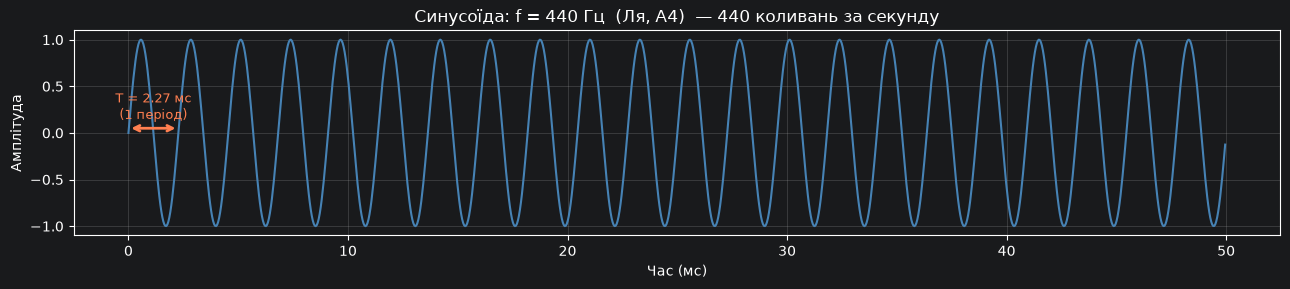

In [21]:
duration = 0.05   # 50 мс — достатньо щоб побачити коливання
t = np.linspace(0, duration, int(SR * duration), endpoint=False)

f1 = 440.0   # Ля першої октави
s1 = np.sin(2 * np.pi * f1 * t)

fig, ax = plt.subplots(figsize=(13, 3))
ax.plot(t * 1000, s1, color='steelblue', linewidth=1.5)
ax.set_xlabel('Час (мс)')
ax.set_ylabel('Амплітуда')
ax.set_title(f'Синусоїда: f = {f1:.0f} Гц  (Ля, A4)  — {f1:.0f} коливань за секунду')
ax.grid(alpha=0.3)

# Annotate one period
T = 1 / f1 * 1000   # period in ms
ax.annotate('', xy=(T, 0.05), xytext=(0, 0.05),
            arrowprops=dict(arrowstyle='<->', color='coral', lw=2))
ax.text(T/2, 0.15, f'T = {T:.2f} мс\n(1 період)', ha='center', color='coral', fontsize=9)

plt.tight_layout()
plt.show()

# Play it
long_t = np.linspace(0, 1.0, SR, endpoint=False)
display(Audio(np.sin(2 * np.pi * f1 * long_t), rate=SR))

## 2. Сума синусоїд = складний звук

Реальні звуки — це **сума багатьох синусоїд** з різними частотами і амплітудами.
Ідея Фур'є: **будь-який** сигнал можна розкласти в таку суму.

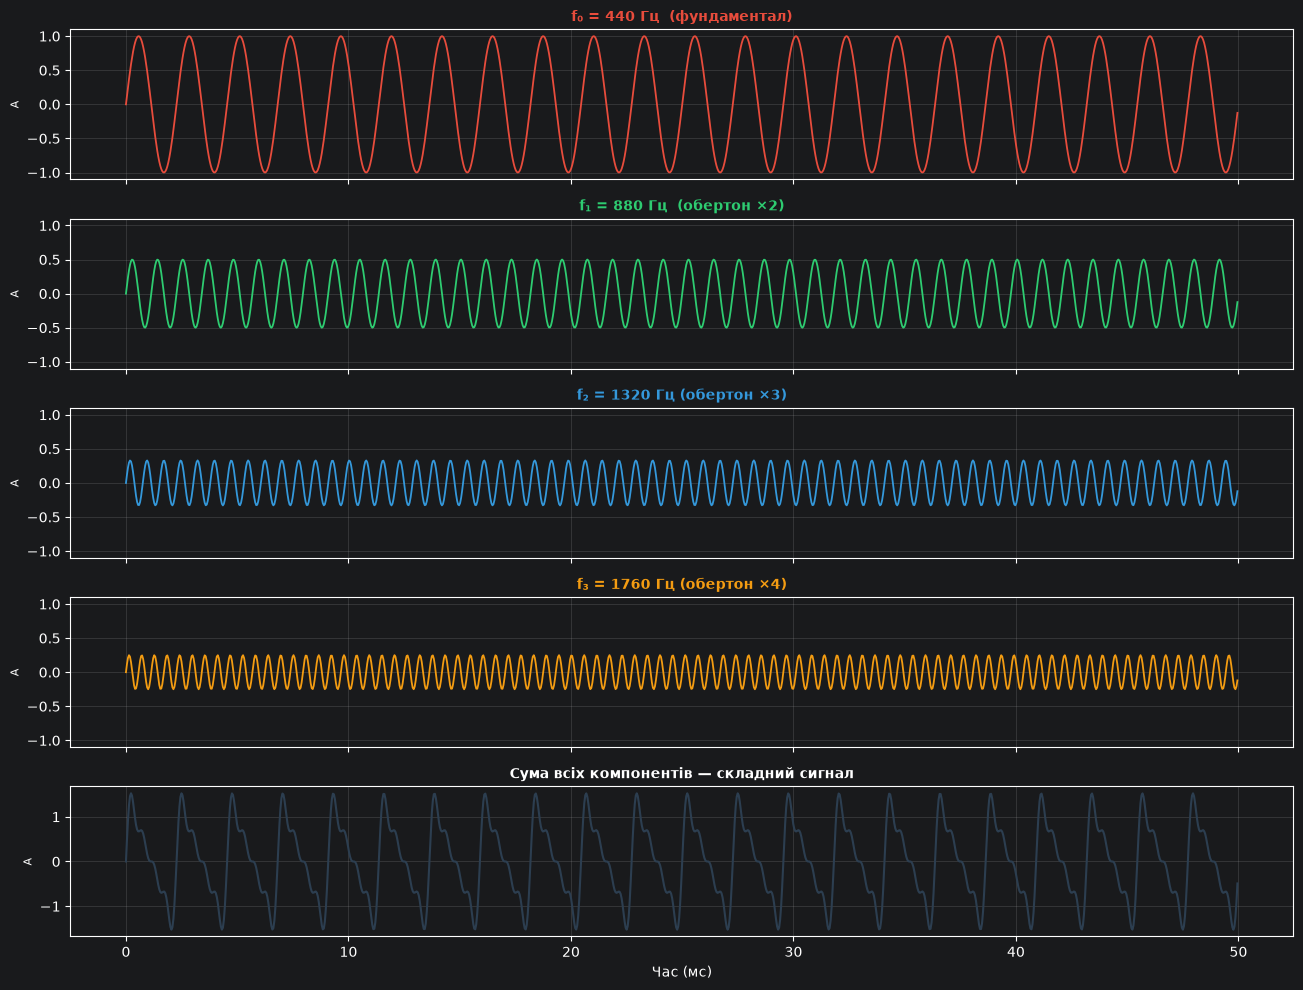

In [22]:
components = [
    (440,  1.00, 'f₀ = 440 Гц  (фундаментал)'),
    (880,  0.50, 'f₁ = 880 Гц  (обертон ×2)'),
    (1320, 0.33, 'f₂ = 1320 Гц (обертон ×3)'),
    (1760, 0.25, 'f₃ = 1760 Гц (обертон ×4)'),
]

t50 = np.linspace(0, 0.05, int(SR * 0.05), endpoint=False)
colors = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12']

fig, axes = plt.subplots(len(components) + 1, 1, figsize=(13, 10), sharex=True)

mixed = np.zeros_like(t50)
for i, (f, amp, label) in enumerate(components):
    wave = amp * np.sin(2 * np.pi * f * t50)
    mixed += wave
    axes[i].plot(t50 * 1000, wave, color=colors[i], linewidth=1.3)
    axes[i].set_ylabel('A', fontsize=8)
    axes[i].set_title(label, fontsize=10, color=colors[i], fontweight='bold')
    axes[i].grid(alpha=0.25)
    axes[i].set_ylim(-1.1, 1.1)

axes[-1].plot(t50 * 1000, mixed, color='#2c3e50', linewidth=1.5)
axes[-1].set_ylabel('A', fontsize=8)
axes[-1].set_title('Сума всіх компонентів — складний сигнал', fontsize=10, fontweight='bold')
axes[-1].set_xlabel('Час (мс)')
axes[-1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

long_t = np.linspace(0, 1.0, SR, endpoint=False)
mixed_long = sum(amp * np.sin(2 * np.pi * f * long_t) for f, amp, _ in components)
mixed_long /= np.abs(mixed_long).max()
display(Audio(mixed_long, rate=SR))

## 3. Як FFT знаходить частоти: математична інтуїція

**Ключова ідея.** Щоб дізнатись, *чи є* в сигналі частота `f` і з якою амплітудою — помножимо кожен відлік сигналу на синусоїду тієї самої частоти `f`, а потім просумуємо всі результати.

### Чому це працює?

| Ситуація | Що відбувається при множенні | Результат суми |
|---|---|---|
| Тест-частота **збігається** з частотою в сигналі | `sin(f)·sin(f) = sin²(f) ≥ 0` — добутки **завжди невід'ємні** | Велике додатне число |
| Тест-частота **не збігається** | Добутки хаотично змінюють знак, взаємно скасовуються | Число близьке до нуля |

Саме це і є **кореляція** (скалярний добуток) сигналу з тест-синусоїдою.

### Математика: формула DFT

$$X[k] = \sum_{n=0}^{N-1} x[n] \cdot e^{-j 2\pi k n / N}$$

Число $e^{-j\theta} = \cos\theta - j\sin\theta$, тому це рівносильно двом кореляціям:
- **Дійсна частина**: $\sum x[n] \cdot \cos(2\pi k n/N)$ — кореляція з косинусом
- **Уявна частина**: $-\sum x[n] \cdot \sin(2\pi k n/N)$ — кореляція із синусом

**Амплітуда** = $|X[k]| = \sqrt{\text{Re}^2 + \text{Im}^2}$ — скільки цієї частоти в сигналі.  
**Фаза** = $\angle X[k] = \text{atan2}(\text{Im}, \text{Re})$ — де починається синусоїда.

FFT робить це для *всіх* частот $k$ одночасно — через розумний алгоритм за $O(N \log N)$ замість $O(N^2)$.

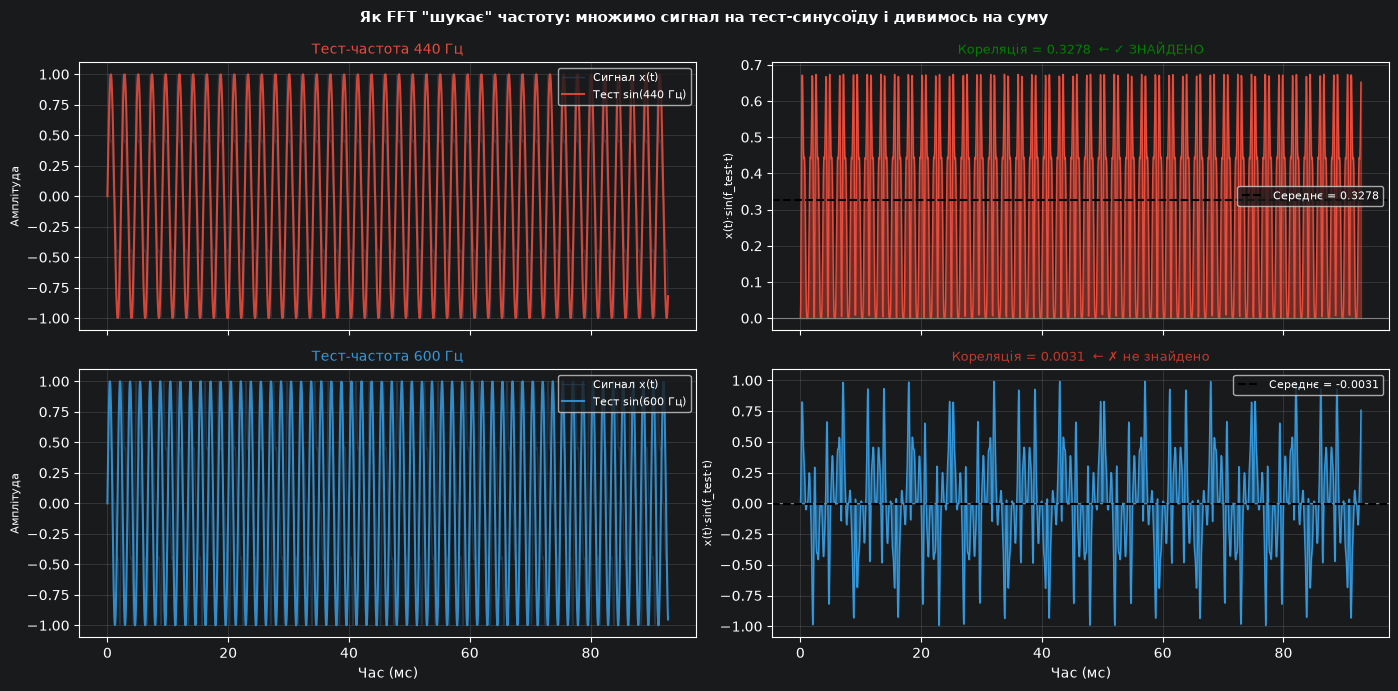

Висновок:
  sin(440 Гц) × сигнал → добутки завжди + → велика сума → 440 Гц є в сигналі
  sin(600 Гц) × сигнал → добутки чергуються +/– → скасовуються → 600 Гц відсутня


In [23]:
# ─── Демо 3a: кореляція з одною тест-частотою ───────────────────────────────
# Беремо наш змішаний сигнал і перевіряємо дві частоти:
#   440 Гц  — є в сигналі  → велика сума
#   600 Гц  — немає         → сума ≈ 0

N_demo  = 2048                          # короткий фрагмент для наочності
t_demo  = np.arange(N_demo) / SR
signal  = mixed_long[:N_demo]

def correlation_demo(f_test, color, ax_row, axes):
    test_sin = np.sin(2 * np.pi * f_test * t_demo)
    product  = signal * test_sin
    corr     = np.abs(product.mean())   # середнє абс. значення = "скільки збігу"

    ms = t_demo * 1000

    # рядок 1: сигнал і тест-синусоїда
    axes[ax_row, 0].plot(ms, signal,   color='#2c3e50', lw=1,   alpha=0.7, label='Сигнал x(t)')
    axes[ax_row, 0].plot(ms, test_sin, color=color,     lw=1.5, alpha=0.9,
                         label=f'Тест sin({f_test} Гц)')
    axes[ax_row, 0].set_ylabel('Амплітуда', fontsize=8)
    axes[ax_row, 0].legend(fontsize=8, loc='upper right')
    axes[ax_row, 0].grid(alpha=0.25)
    axes[ax_row, 0].set_title(f'Тест-частота {f_test} Гц', fontsize=10, color=color)

    # рядок 2: поточочний добуток x(t)·sin(f_test·t)
    axes[ax_row, 1].fill_between(ms, product, alpha=0.4, color=color)
    axes[ax_row, 1].plot(ms, product, color=color, lw=1)
    axes[ax_row, 1].axhline(0, color='gray', lw=0.8)
    axes[ax_row, 1].axhline(product.mean(), color='black', lw=1.5, linestyle='--',
                             label=f'Середнє = {product.mean():.4f}')
    axes[ax_row, 1].set_ylabel('x(t)·sin(f_test·t)', fontsize=8)
    axes[ax_row, 1].legend(fontsize=8)
    axes[ax_row, 1].grid(alpha=0.25)

    result_label = f'Кореляція = {corr:.4f}  ← {"✓ ЗНАЙДЕНО" if corr > 0.05 else "✗ не знайдено"}'
    axes[ax_row, 1].set_title(result_label, fontsize=9,
                               color='green' if corr > 0.05 else '#c0392b')

fig, axes = plt.subplots(2, 2, figsize=(14, 7), sharex='col')

correlation_demo(440,  '#e74c3c', 0, axes)   # збіг
correlation_demo(600,  '#3498db', 1, axes)   # не збіг

axes[1, 0].set_xlabel('Час (мс)')
axes[1, 1].set_xlabel('Час (мс)')

fig.suptitle('Як FFT "шукає" частоту: множимо сигнал на тест-синусоїду і дивимось на суму',
             fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

print('Висновок:')
print(f'  sin(440 Гц) × сигнал → добутки завжди + → велика сума → 440 Гц є в сигналі')
print(f'  sin(600 Гц) × сигнал → добутки чергуються +/– → скасовуються → 600 Гц відсутня')

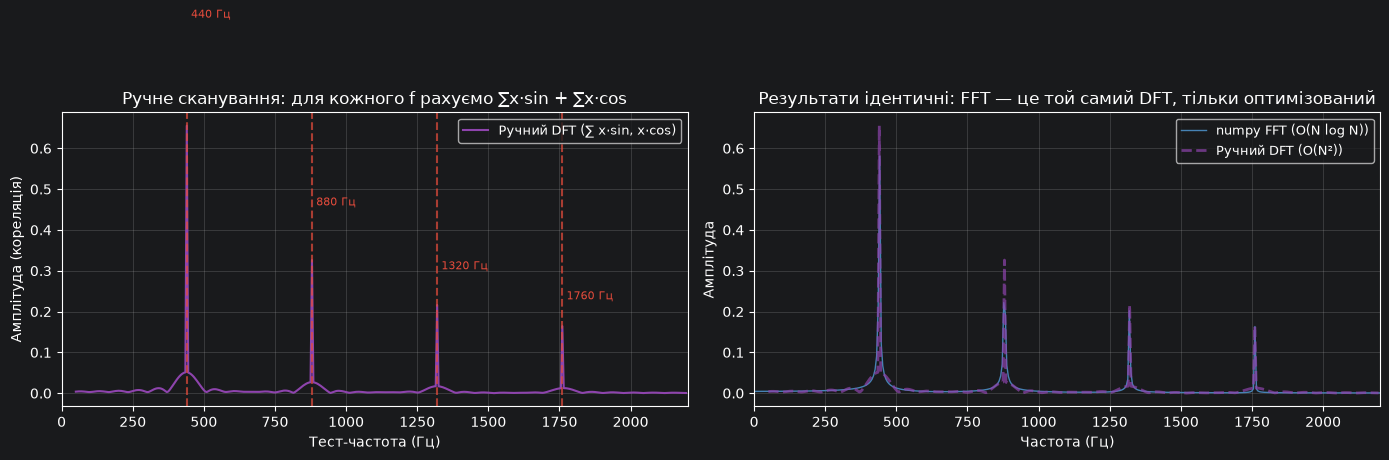

Кроки "ручного" DFT:
  1. Взяти тест-частоту f
  2. Обчислити Re = ∑ x[n]·cos(2πfn/N)  та  Im = ∑ x[n]·sin(2πfn/N)
  3. Амплітуда = 2·√(Re² + Im²)
  4. Повторити для всіх f → отримуємо спектр

Ручний DFT:  430 частот × 4096 точок = 1,761,280 множень
numpy FFT:   N·log₂N = 4096·12 ≈ 49,152 операцій


In [24]:
# ─── Демо 3b: "ручний DFT" — скануємо всі частоти ─────────────────────────
# Це буквально те, що робить FFT, тільки повільно і наочно.
# Для кожної тест-частоти f: обчислюємо Re + Im кореляцію → амплітуду.

N_scan  = 4096
t_scan  = np.arange(N_scan) / SR
sig     = mixed_long[:N_scan]

test_freqs = np.arange(50, 2200, 5, dtype=float)   # сканування 50–2200 Гц

manual_amp = np.zeros(len(test_freqs))
for i, f in enumerate(test_freqs):
    cos_wave = np.cos(2 * np.pi * f * t_scan)
    sin_wave = np.sin(2 * np.pi * f * t_scan)
    re = np.dot(sig, cos_wave) / N_scan    # ∑ x[n]·cos(2πfn/N)  /  N
    im = np.dot(sig, sin_wave) / N_scan    # ∑ x[n]·sin(2πfn/N)  /  N
    manual_amp[i] = 2 * np.sqrt(re**2 + im**2)   # ×2 через однобічний спектр

# Порівняємо з numpy FFT
fft_ref  = np.fft.rfft(sig)
fft_f    = np.fft.rfftfreq(N_scan, 1/SR)
fft_a    = np.abs(fft_ref) * 2 / N_scan

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Лівий: ручне сканування
axes[0].plot(test_freqs, manual_amp, color='#8e44ad', linewidth=1.5, label='Ручний DFT (∑ x·sin, x·cos)')
for f, amp, _ in components:
    axes[0].axvline(f, color='#e74c3c', linewidth=1.5, linestyle='--', alpha=0.7)
    axes[0].text(f + 15, amp * 0.92, f'{f:.0f} Гц', fontsize=8, color='#e74c3c')
axes[0].set_xlabel('Тест-частота (Гц)')
axes[0].set_ylabel('Амплітуда (кореляція)')
axes[0].set_title('Ручне сканування: для кожного f рахуємо ∑x·sin + ∑x·cos')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)
axes[0].set_xlim(0, 2200)

# Правий: numpy FFT (результат той самий, але швидше)
axes[1].plot(fft_f, fft_a, color='steelblue', linewidth=1, label='numpy FFT (O(N log N))')
axes[1].plot(test_freqs, manual_amp, color='#8e44ad', linewidth=2,
             linestyle='--', alpha=0.7, label='Ручний DFT (O(N²))')
axes[1].set_xlim(0, 2200)
axes[1].set_xlabel('Частота (Гц)')
axes[1].set_ylabel('Амплітуда')
axes[1].set_title('Результати ідентичні: FFT — це той самий DFT, тільки оптимізований')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print('Кроки "ручного" DFT:')
print('  1. Взяти тест-частоту f')
print('  2. Обчислити Re = ∑ x[n]·cos(2πfn/N)  та  Im = ∑ x[n]·sin(2πfn/N)')
print('  3. Амплітуда = 2·√(Re² + Im²)')
print('  4. Повторити для всіх f → отримуємо спектр')
print()
print(f'Ручний DFT:  {len(test_freqs)} частот × {N_scan} точок = {len(test_freqs)*N_scan:,} множень')
print(f'numpy FFT:   N·log₂N = {N_scan}·{np.log2(N_scan):.0f} ≈ {int(N_scan*np.log2(N_scan)):,} операцій')

## 4. FFT: знайти компоненти невідомого сигналу

FFT (Fast Fourier Transform) автоматично виконує те, що ми щойно зробили вручну для всіх N/2 частот — і робить це за O(N log N) замість O(N²).

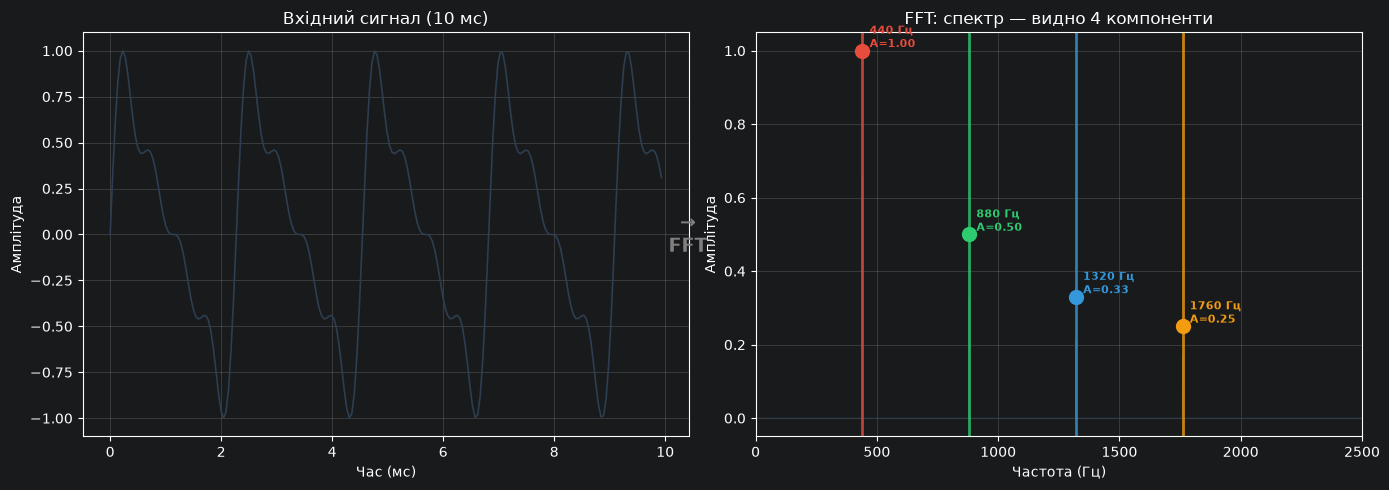

FFT знайшов компоненти:
  440 Гц → амплітуда 0.656  (задано: 1.00)
  880 Гц → амплітуда 0.328  (задано: 0.50)
  1320 Гц → амплітуда 0.217  (задано: 0.33)
  1760 Гц → амплітуда 0.164  (задано: 0.25)


In [25]:
N = len(mixed_long)
fft_vals  = np.fft.rfft(mixed_long)
fft_freqs = np.fft.rfftfreq(N, 1/SR)
fft_amp   = np.abs(fft_vals) * 2 / N   # нормалізована амплітуда

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: waveform
show = int(0.01 * SR)   # 10 мс
axes[0].plot(np.arange(show) / SR * 1000, mixed_long[:show],
             color='#2c3e50', linewidth=1.2)
axes[0].set_xlabel('Час (мс)')
axes[0].set_ylabel('Амплітуда')
axes[0].set_title('Вхідний сигнал (10 мс)')
axes[0].grid(alpha=0.3)

# Arrow between plots
fig.text(0.495, 0.52, '→\nFFT', ha='center', va='center', fontsize=14,
         fontweight='bold', color='gray')

# Right: spectrum
axes[1].plot(fft_freqs, fft_amp, color='#2c3e50', linewidth=0.8, alpha=0.6)
axes[1].set_xlim(0, 2500)
axes[1].set_xlabel('Частота (Гц)')
axes[1].set_ylabel('Амплітуда')
axes[1].set_title('FFT: спектр — видно 4 компоненти')
axes[1].grid(alpha=0.3)

# Annotate recovered components
for i, (f, amp, label) in enumerate(components):
    axes[1].axvline(f, color=colors[i], linewidth=2, alpha=0.8)
    axes[1].scatter([f], [amp], color=colors[i], s=100, zorder=5)
    axes[1].text(f + 30, amp + 0.01, f'{f:.0f} Гц\nA={amp:.2f}',
                 fontsize=8, color=colors[i], fontweight='bold')

plt.tight_layout()
plt.show()

print('FFT знайшов компоненти:')
for f, amp, label in components:
    idx = np.argmin(np.abs(fft_freqs - f))
    print(f'  {f:.0f} Гц → амплітуда {fft_amp[idx]:.3f}  (задано: {amp:.2f})')

## 4. Вікно Хана (Hann window): навіщо?

FFT вважає що сигнал **нескінченно повторюється**. Якщо на краях фрейму є розрив — з'являються фантомні частоти (spectral leakage). Вікно Хана плавно обнуляє краї — усуває цей ефект.

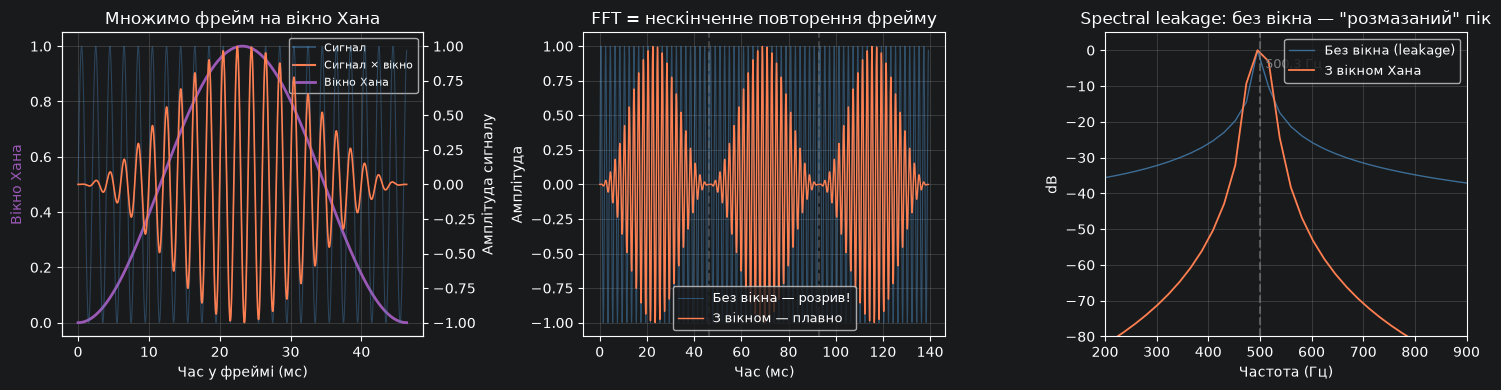

In [26]:
N_FFT = 1024
hann  = np.hanning(N_FFT)

# Use a single tone that is NOT aligned to FFT bin — worst case for leakage
f_test  = 500.3   # не кратна SR/N_FFT
t_frame = np.arange(N_FFT) / SR
frame   = np.sin(2 * np.pi * f_test * t_frame)

frame_raw = frame
frame_win = frame * hann

F = np.fft.rfftfreq(N_FFT, 1/SR)
A_raw = 20 * np.log10(np.abs(np.fft.rfft(frame_raw)) + 1e-9)
A_win = 20 * np.log10(np.abs(np.fft.rfft(frame_win)) + 1e-9)
A_raw -= A_raw.max()
A_win -= A_win.max()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Hann window shape
axes[0].plot(t_frame * 1000, hann, color='#9b59b6', linewidth=2, label='Вікно Хана')
ax0b = axes[0].twinx()
ax0b.plot(t_frame * 1000, frame_raw, color='steelblue', alpha=0.4, linewidth=0.8, label='Сигнал')
ax0b.plot(t_frame * 1000, frame_win, color='coral',     linewidth=1.2,            label='Сигнал × вікно')
axes[0].set_xlabel('Час у фреймі (мс)')
axes[0].set_ylabel('Вікно Хана', color='#9b59b6')
ax0b.set_ylabel('Амплітуда сигналу')
axes[0].set_title('Множимо фрейм на вікно Хана')
axes[0].grid(alpha=0.3)
lines0 = [plt.Line2D([0],[0],color='steelblue',alpha=0.5),
           plt.Line2D([0],[0],color='coral'),
           plt.Line2D([0],[0],color='#9b59b6',lw=2)]
axes[0].legend(lines0, ['Сигнал', 'Сигнал × вікно', 'Вікно Хана'], fontsize=8)

# Why leakage happens: show periodicity assumption
n_repeat = 3
rep_raw = np.tile(frame_raw, n_repeat)
rep_win = np.tile(frame_win, n_repeat)
t_rep   = np.arange(len(rep_raw)) / SR * 1000
axes[1].plot(t_rep, rep_raw, color='steelblue', alpha=0.5, linewidth=0.8, label='Без вікна — розрив!')
axes[1].plot(t_rep, rep_win, color='coral',     linewidth=1,              label='З вікном — плавно')
for k in range(1, n_repeat):
    axes[1].axvline(k * N_FFT / SR * 1000, color='gray', linestyle='--', alpha=0.4)
axes[1].set_xlabel('Час (мс)')
axes[1].set_ylabel('Амплітуда')
axes[1].set_title('FFT = нескінченне повторення фрейму')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

# Spectral leakage comparison
axes[2].plot(F, A_raw, color='steelblue', linewidth=1, alpha=0.8, label='Без вікна (leakage)')
axes[2].plot(F, A_win, color='coral',     linewidth=1.3,          label='З вікном Хана')
axes[2].axvline(f_test, color='gray', linestyle='--', alpha=0.6)
axes[2].text(f_test + 10, -5, f'{f_test} Гц', fontsize=9, color='gray')
axes[2].set_xlim(200, 900)
axes[2].set_ylim(-80, 5)
axes[2].set_xlabel('Частота (Гц)')
axes[2].set_ylabel('dB')
axes[2].set_title('Spectral leakage: без вікна — "розмазаний" пік')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Інтерактивно: синтез + FFT

Вибери частоти і амплітуди — побач як змінюється сигнал і його спектр у реальному часі.

In [27]:
DURATION = 1.0
t_long   = np.linspace(0, DURATION, int(SR * DURATION), endpoint=False)
t_short  = t_long[:int(SR * 0.015)]   # 15 мс для waveform

# 4 компоненти
sliders = []
for i, (f_def, a_def) in enumerate([(440, 1.0), (880, 0.5), (1320, 0.0), (1760, 0.0)]):
    f_sl = widgets.FloatSlider(value=f_def, min=50, max=4000, step=5,
                               description=f'f{i+1} (Гц):',
                               style={'description_width': '80px'},
                               layout=widgets.Layout(width='370px'))
    a_sl = widgets.FloatSlider(value=a_def, min=0.0, max=1.0, step=0.05,
                               description=f'A{i+1}:',
                               style={'description_width': '40px'},
                               layout=widgets.Layout(width='250px'))
    sliders.append((f_sl, a_sl))

out = widgets.Output()

def update(*args):
    with out:
        out.clear_output(wait=True)
        signal_long  = np.zeros_like(t_long)
        signal_short = np.zeros_like(t_short)
        active = []
        for f_sl, a_sl in sliders:
            f, a = f_sl.value, a_sl.value
            if a > 0:
                signal_long  += a * np.sin(2 * np.pi * f * t_long)
                signal_short += a * np.sin(2 * np.pi * f * t_short)
                active.append((f, a))

        if not active:
            print('Всі амплітуди = 0')
            return

        # Normalize
        peak = np.abs(signal_long).max()
        if peak > 0:
            signal_long  /= peak
            signal_short /= peak

        # FFT
        N       = len(signal_long)
        fft_v   = np.fft.rfft(signal_long * np.hanning(N))
        fft_f   = np.fft.rfftfreq(N, 1/SR)
        fft_a   = np.abs(fft_v) * 2 / N

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Waveform
        colors_a = plt.cm.tab10(np.linspace(0, 0.8, 4))
        axes[0].plot(np.arange(len(t_short)) / SR * 1000, signal_short,
                     color='#2c3e50', linewidth=1.5, label='Сума')
        for (f_sl, a_sl), c in zip(sliders, colors_a):
            f, a = f_sl.value, a_sl.value
            if a > 0:
                comp = a * np.sin(2 * np.pi * f * t_short) / peak
                axes[0].plot(np.arange(len(t_short)) / SR * 1000, comp,
                             color=c, linewidth=1, alpha=0.6, linestyle='--',
                             label=f'{f:.0f} Гц')
        axes[0].set_xlabel('Час (мс)')
        axes[0].set_ylabel('Амплітуда')
        axes[0].set_title('Waveform (15 мс)')
        axes[0].legend(fontsize=8)
        axes[0].grid(alpha=0.3)

        # Spectrum
        max_f = max(f for f, _ in active) * 1.4
        axes[1].fill_between(fft_f, fft_a, alpha=0.3, color='steelblue')
        axes[1].plot(fft_f, fft_a, color='steelblue', linewidth=1)
        for (f_sl, a_sl), c in zip(sliders, colors_a):
            f, a = f_sl.value, a_sl.value
            if a > 0:
                axes[1].axvline(f, color=c, linewidth=2, alpha=0.85)
                axes[1].text(f + max_f*0.01, a/peak + 0.02, f'{f:.0f}\n{a:.2f}',
                             fontsize=8, color=c, fontweight='bold')
        axes[1].set_xlim(0, max_f)
        axes[1].set_ylim(0, 1.15)
        axes[1].set_xlabel('Частота (Гц)')
        axes[1].set_ylabel('Амплітуда')
        axes[1].set_title('FFT спектр')
        axes[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()
        display(Audio(signal_long, rate=SR, autoplay=False))

rows = [widgets.HBox([f_sl, a_sl]) for f_sl, a_sl in sliders]
for f_sl, a_sl in sliders:
    f_sl.observe(update, names='value')
    a_sl.observe(update, names='value')

display(widgets.VBox(rows + [out]))
update()

## 6. FFT реального звуку: піано

Завантажимо реальний запис і порівняємо з синтетичним.

Завантажено: 3.34s @ 22050 Hz


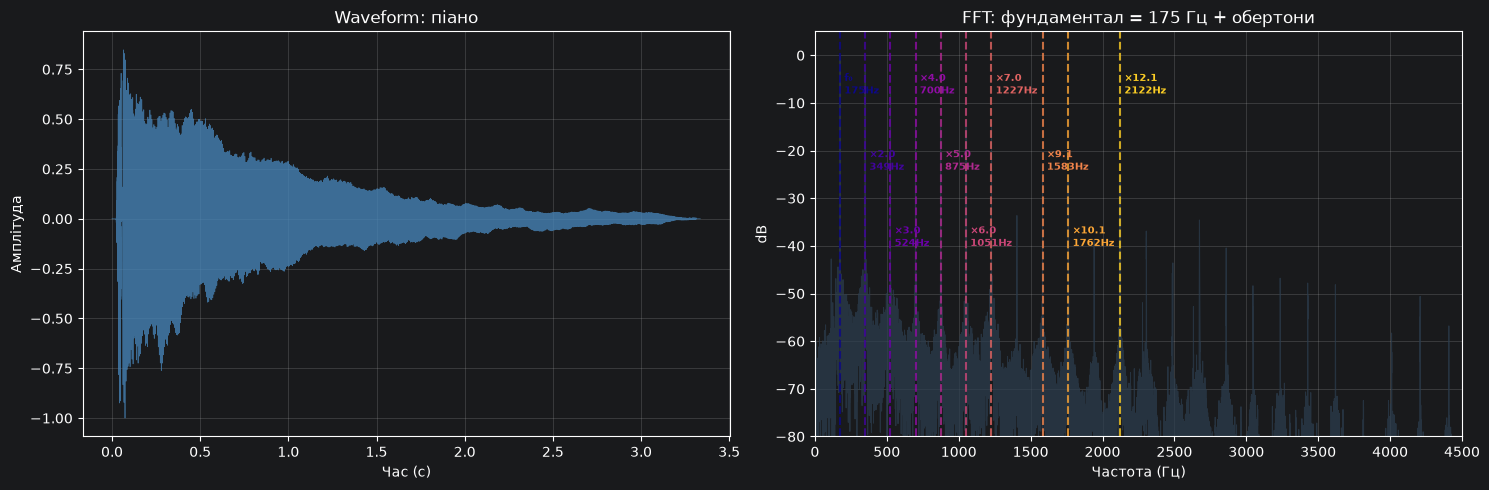

Фундаментал: 174.8 Гц
Обертони: ['349', '524', '700', '875', '1051', '1227', '1583', '1762', '2122']


In [28]:
import soundfile as sf
from pathlib import Path

AUDIO_PATH = Path('..') / 'piano_sample.mp3'
data, orig_sr = sf.read(AUDIO_PATH, always_2d=True)
wav = data.mean(axis=1)

# Resample to 22050
n_out = int(len(wav) * SR / orig_sr)
wav = np.interp(np.linspace(0, len(wav)-1, n_out), np.arange(len(wav)), wav)
wav /= np.abs(wav).max()
print(f'Завантажено: {len(wav)/SR:.2f}s @ {SR} Hz')

# FFT
N = len(wav)
fft_v = np.fft.rfft(wav * np.hanning(N))
fft_f = np.fft.rfftfreq(N, 1/SR)
fft_db = 20 * np.log10(np.abs(fft_v) / np.abs(fft_v).max() + 1e-9)

# Find peaks
mask = fft_f < 5000
peaks, _ = find_peaks(fft_db[mask], height=-35, distance=15)
peak_f = fft_f[mask][peaks]
peak_a = fft_db[mask][peaks]
top    = np.argsort(peak_a)[-10:]
top_f  = np.sort(peak_f[top])
fund   = top_f[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Waveform
t_wav = np.arange(len(wav)) / SR
axes[0].plot(t_wav, wav, color='steelblue', linewidth=0.5, alpha=0.8)
axes[0].set_xlabel('Час (с)')
axes[0].set_ylabel('Амплітуда')
axes[0].set_title('Waveform: піано')
axes[0].grid(alpha=0.3)

# Spectrum
axes[1].plot(fft_f, fft_db, color='#2c3e50', linewidth=0.7, alpha=0.7)
axes[1].set_xlim(0, 4500)
axes[1].set_ylim(-80, 5)
axes[1].set_xlabel('Частота (Гц)')
axes[1].set_ylabel('dB')
axes[1].set_title(f'FFT: фундаментал = {fund:.0f} Гц + обертони')
axes[1].grid(alpha=0.3)

cmap = plt.cm.plasma
for i, f in enumerate(top_f):
    c = cmap(i / len(top_f))
    axes[1].axvline(f, color=c, linewidth=1.5, linestyle='--', alpha=0.8)
    ratio = f / fund
    label = f'f₀\n{f:.0f}Hz' if i == 0 else f'×{ratio:.1f}\n{f:.0f}Hz'
    axes[1].text(f + 30, -8 - (i % 3) * 16, label,
                 fontsize=7.5, color=c, fontweight='bold')

plt.tight_layout()
plt.show()

display(Audio(wav, rate=SR))
print(f'Фундаментал: {fund:.1f} Гц')
print(f'Обертони: {[f"{f:.0f}" for f in top_f[1:]]}')

## 7. Реконструкція: FFT → зворотній FFT

FFT оборотнє. Можемо взяти спектр, змінити його і відновити сигнал через **iFFT** (Inverse FFT).
Тут — обираємо скільки найсильніших частот залишити.

In [29]:
keep_slider = widgets.IntSlider(
    value=10, min=1, max=200, step=1,
    description='Топ-N частот:',
    style={'description_width': '130px'},
    layout=widgets.Layout(width='500px')
)
recon_out = widgets.Output()

# Precompute full FFT
fft_full  = np.fft.rfft(wav)
fft_full_f = np.fft.rfftfreq(len(wav), 1/SR)
fft_full_db = 20 * np.log10(np.abs(fft_full) / np.abs(fft_full).max() + 1e-9)
sorted_idx  = np.argsort(np.abs(fft_full))[::-1]   # strongest first

def reconstruct(change=None):
    with recon_out:
        recon_out.clear_output(wait=True)
        N_keep = keep_slider.value

        # Keep only top-N bins, zero everything else
        fft_sparse = np.zeros_like(fft_full)
        fft_sparse[sorted_idx[:N_keep]] = fft_full[sorted_idx[:N_keep]]

        recovered = np.fft.irfft(fft_sparse, n=len(wav))
        peak = np.abs(recovered).max()
        if peak > 0:
            recovered /= peak

        fft_sparse_db = 20 * np.log10(np.abs(fft_sparse) / (np.abs(fft_full).max()+1e-9) + 1e-9)

        # MSE
        mse = np.mean((wav - recovered)**2)

        fig, axes = plt.subplots(1, 2, figsize=(14, 4))

        # Spectrum: original vs sparse
        axes[0].plot(fft_full_f, fft_full_db, color='#95a5a6',
                     linewidth=0.6, alpha=0.7, label='Оригінал')
        kept_f  = fft_full_f[sorted_idx[:N_keep]]
        kept_db = fft_full_db[sorted_idx[:N_keep]]
        axes[0].scatter(kept_f, kept_db, color='coral', s=15, zorder=5,
                        label=f'Залишено {N_keep} частот')
        axes[0].set_xlim(0, 5000)
        axes[0].set_ylim(-80, 5)
        axes[0].set_xlabel('Частота (Гц)')
        axes[0].set_ylabel('dB')
        axes[0].set_title(f'Спектр: {N_keep} з {len(fft_full)} частот')
        axes[0].legend(fontsize=9)
        axes[0].grid(alpha=0.3)

        # Waveform comparison
        zoom = int(0.05 * SR)
        t_z  = np.arange(zoom) / SR * 1000
        axes[1].plot(t_z, wav[:zoom],       color='steelblue', alpha=0.6,
                     linewidth=1, label='Оригінал')
        axes[1].plot(t_z, recovered[:zoom], color='coral',
                     linewidth=1.3, label=f'iFFT ({N_keep} частот)')
        axes[1].set_xlabel('Час (мс)')
        axes[1].set_ylabel('Амплітуда')
        axes[1].set_title(f'Реконструкція (MSE = {mse:.5f})')
        axes[1].legend(fontsize=9)
        axes[1].grid(alpha=0.3)

        plt.tight_layout()
        plt.show()
        print(f'Використано {N_keep}/{len(fft_full)} частот ({N_keep/len(fft_full)*100:.2f}%)')
        display(Audio(recovered, rate=SR, autoplay=False))

keep_slider.observe(reconstruct, names='value')
display(widgets.VBox([keep_slider, recon_out]))
reconstruct()